# Modelo de Classificação: Cats vs Dogs

* Esse trabalho busca classificar imagens de gatos e cachorros através de uma CNN, inspirada na AlexNet. 
* As imagens foram obtidas através de uma base de dados do kaggle com aproximadamente 25mil dados, que foram utilizados para treinar e testar o modelo posteriormente. 
* Trabalho realizado para o picme de ``Processamento de Imagens Cardíacas`` com o intuito de praticar a teoria estudada até o momento atual e motivar uma competição entre os estudantes envolvidos. 

## 1. Configuraçaõ Inicial

In [1]:
%pip install kagglehub torch numpy pillow scipy

Note: you may need to restart the kernel to use updated packages.


In [2]:
import hashlib
import os
from collections import Counter, defaultdict

import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from PIL import Image
from scipy.spatial import cKDTree
from torch.utils.data import DataLoader, Subset, TensorDataset

SEED = 18
rng = np.random.default_rng(SEED)
torch.manual_seed(SEED)

In [3]:
import kagglehub

caminho = kagglehub.dataset_download("bhavikjikadara/dog-and-cat-classification-dataset")
print(caminho)

/home/al.dulce.costa/.cache/kagglehub/datasets/bhavikjikadara/dog-and-cat-classification-dataset/versions/1


## 2. Exploração dos Dados

In [4]:
for pasta, subpastas, arquivos in os.walk(caminho):
    print(pasta, "-", len(arquivos), "arquivos")

/home/al.dulce.costa/.cache/kagglehub/datasets/bhavikjikadara/dog-and-cat-classification-dataset/versions/1 - 0 arquivos
/home/al.dulce.costa/.cache/kagglehub/datasets/bhavikjikadara/dog-and-cat-classification-dataset/versions/1/PetImages - 0 arquivos
/home/al.dulce.costa/.cache/kagglehub/datasets/bhavikjikadara/dog-and-cat-classification-dataset/versions/1/PetImages/Dog - 12499 arquivos
/home/al.dulce.costa/.cache/kagglehub/datasets/bhavikjikadara/dog-and-cat-classification-dataset/versions/1/PetImages/Cat - 12499 arquivos


In [5]:
info = []          # um item por arquivo que abriu como imagem
nao_abriram = []   # arquivos que não abriram como imagem

for pasta, _, nomes in os.walk(caminho):
    for nome in nomes:
        arquivo = os.path.join(pasta, nome)
        try:
            with Image.open(arquivo) as img:
                img.load()
                largura, altura = img.size
                modo = img.mode
        except Exception:
            nao_abriram.append(arquivo)
            continue
        with open(arquivo, "rb") as f:
            impressao = hashlib.md5(f.read()).hexdigest()
        info.append({
            "arquivo": arquivo,
            "classe": os.path.basename(pasta),
            "largura": largura,
            "altura": altura,
            "modo": modo,
            "hash": impressao,
        })

print("Imagens que abriram:", len(info))
print("Arquivos que não abriram:", len(nao_abriram), nao_abriram[:10])
print("Pastas (classes):", Counter(d["classe"] for d in info))
print("Modos de cor:", Counter(d["modo"] for d in info))

/opt/anaconda3/envs/ambiente_aluno/lib/python3.13/site-packages/PIL/TiffImagePlugin.py:950: UserWarning: Truncated File Read
  warnings.warn(str(msg))


Imagens que abriram: 24998
Arquivos que não abriram: 0 []
Pastas (classes): Counter({'Dog': 12499, 'Cat': 12499})
Modos de cor: Counter({'RGB': 24931, 'P': 57, 'L': 5, 'CMYK': 3, 'RGBA': 2})


* Para observar alguns erros de classificação ou se existem arquivos idênticos (e retirá-las posteriormente)

In [6]:
por_hash = defaultdict(list)
for d in info:
    por_hash[d["hash"]].append(d)

grupos_identicos = [g for g in por_hash.values() if len(g) > 1]
em_classes_diferentes = [g for g in grupos_identicos if len({d["classe"] for d in g}) > 1]

print("Grupos de arquivos idênticos:", len(grupos_identicos))
print("Desses, em classes diferentes:", len(em_classes_diferentes))
for g in em_classes_diferentes[:10]:
    print([d["arquivo"] for d in g])

Grupos de arquivos idênticos: 28
Desses, em classes diferentes: 2
['/home/al.dulce.costa/.cache/kagglehub/datasets/bhavikjikadara/dog-and-cat-classification-dataset/versions/1/PetImages/Dog/10401.jpg', '/home/al.dulce.costa/.cache/kagglehub/datasets/bhavikjikadara/dog-and-cat-classification-dataset/versions/1/PetImages/Dog/10797.jpg', '/home/al.dulce.costa/.cache/kagglehub/datasets/bhavikjikadara/dog-and-cat-classification-dataset/versions/1/PetImages/Dog/2877.jpg', '/home/al.dulce.costa/.cache/kagglehub/datasets/bhavikjikadara/dog-and-cat-classification-dataset/versions/1/PetImages/Cat/11565.jpg']
['/home/al.dulce.costa/.cache/kagglehub/datasets/bhavikjikadara/dog-and-cat-classification-dataset/versions/1/PetImages/Dog/8736.jpg', '/home/al.dulce.costa/.cache/kagglehub/datasets/bhavikjikadara/dog-and-cat-classification-dataset/versions/1/PetImages/Cat/8456.jpg']


In [8]:
# Grupos com classes diferentes saem inteiros; nos outros, fica um arquivo só.
imagens = [g[0] for g in por_hash.values() if len({d["classe"] for d in g}) == 1]

def impressao_visual(arquivo):
    # Versão 9 x 8 em cinza: cada pixel é comparado com o vizinho da direita.
    with Image.open(arquivo) as im:
        cinza = np.asarray(im.convert("L").resize((9, 8), Image.BILINEAR), dtype=np.int16)
    return (cinza[:, 1:] > cinza[:, :-1]).tobytes()

# Imagens quase idênticas ficam com a mesma origem e vão para o mesmo lado na divisão.
origens = {}
for d in imagens:
    d["origem"] = origens.setdefault(impressao_visual(d["arquivo"]), len(origens))

print("Imagens depois de tirar as repetidas:", len(imagens))
print("Origens diferentes:", len(origens))

Imagens depois de tirar as repetidas: 24966
Origens diferentes: 24962


* Padronizar tamanho das imagens

In [ ]:
# A rede precisa de pelo menos 94 px em cada lado.
imagens = [d for d in imagens if min(d["largura"], d["altura"]) >= 94]
print("Imagens com pelo menos 94 px em cada lado:", len(imagens))

menor = min(imagens, key=lambda d: d["largura"] * d["altura"])
LARGURA, ALTURA = menor["largura"], menor["altura"]
mesma_area = {(d["largura"], d["altura"]) for d in imagens
              if d["largura"] * d["altura"] == LARGURA * ALTURA}

print("Tamanho-alvo:", LARGURA, "x", ALTURA, "(largura x altura)")
print("Formatos com essa mesma área:", mesma_area)
assert len(mesma_area) == 1, "DECIDIR: há mais de um formato com a menor área."

Imagens com pelo menos 94 px em cada lado: 24822
Tamanho-alvo: 100 x 94 (largura x altura)
Formatos com essa mesma área: {(100, 94)}


In [10]:
def valor_na_posicao(img, ys, xs):
    # img: (altura, largura, 3). ys, xs: posições na imagem original, que podem ser quebradas.
    # Devolve um array (quantidade de posições, 3) com o valor de cada canal.
    h, w = img.shape[:2]
    y0 = np.clip(np.floor(ys).astype(int), 0, h - 1)
    y1 = np.clip(np.ceil(ys).astype(int), 0, h - 1)
    x0 = np.clip(np.floor(xs).astype(int), 0, w - 1)
    x1 = np.clip(np.ceil(xs).astype(int), 0, w - 1)
    # O maior valor entre os 4 pixels em volta da posição, canal por canal
    return np.max([img[y0, x0], img[y0, x1], img[y1, x0], img[y1, x1]], axis=0)

In [11]:
def redimensionar(img):
    h, w = img.shape[:2]
    # Posição, na imagem original, do centro de cada pixel da imagem nova
    ys = (np.arange(ALTURA) + 0.5) * h / ALTURA - 0.5
    xs = (np.arange(LARGURA) + 0.5) * w / LARGURA - 0.5
    yy, xx = np.meshgrid(ys, xs, indexing="ij")
    return valor_na_posicao(img, yy.ravel(), xx.ravel()).reshape(ALTURA, LARGURA, 3)

## 3. Medidas de Regularização 

#### Data Augmentation

-> Rotação 15° no sentido horário

In [12]:
def girar_horario(img, graus=15):
    h, w = img.shape[:2]
    cy, cx = (h - 1) / 2, (w - 1) / 2
    t = np.deg2rad(graus)

    # Para cada pixel da imagem girada, de onde ele vem na original
    yy, xx = np.meshgrid(np.arange(h), np.arange(w), indexing="ij")
    dy, dx = yy - cy, xx - cx
    xs = dx * np.cos(t) + dy * np.sin(t) + cx
    ys = -dx * np.sin(t) + dy * np.cos(t) + cy
    dentro = (xs >= 0) & (xs <= w - 1) & (ys >= 0) & (ys <= h - 1)

    nova = np.zeros((h, w, 3), dtype=np.float32)
    nova[dentro] = valor_na_posicao(img, ys[dentro], xs[dentro])

    # Cantos vazios: média dos 3 pixels válidos mais próximos, canal por canal
    validos = np.argwhere(dentro)
    vazios = np.argwhere(~dentro)
    if len(vazios) > 0:
        _, vizinhos = cKDTree(validos).query(vazios, k=3)
        pos = validos[vizinhos]                      # (vazios, 3 vizinhos, 2 coordenadas)
        nova[vazios[:, 0], vazios[:, 1]] = nova[pos[..., 0], pos[..., 1]].mean(axis=1)
    return nova

#### Adicionar Ruído

In [13]:
def adicionar_ruido(img):
    ruidosa = img + rng.normal(0, 2, size=img.shape)
    return np.clip(ruidosa, 0, 255).astype(np.float32)

#### Aplicação em alguns dados selecionados aleatoriamente

In [14]:
n = len(imagens)
ordem = rng.permutation(n)
n_rotacao = round(0.10 * n)
n_ruido = round(0.10 * n)
vao_girar = set(ordem[:n_rotacao].tolist())
vao_ruido = set(ordem[n_rotacao:n_rotacao + n_ruido].tolist())
print("Vão ganhar uma versão girada:", len(vao_girar), "| com ruído:", len(vao_ruido))

Vão ganhar uma versão girada: 2482 | com ruído: 2482


In [15]:
classes = sorted({d["classe"] for d in imagens})
X, y, grupo = [], [], []

for i, d in enumerate(imagens):
    with Image.open(d["arquivo"]) as im:
        img = np.asarray(im.convert("RGB"), dtype=np.float32)   # valores de 0 a 255

    # A rotação é feita antes de redimensionar; o ruído, depois.
    base = redimensionar(img)
    versoes = [base]
    if i in vao_girar:
        versoes.append(redimensionar(girar_horario(img)))
    elif i in vao_ruido:
        versoes.append(adicionar_ruido(base))

    for v in versoes:
        X.append(v)
        y.append(classes.index(d["classe"]))
        grupo.append(d["origem"])   # a versão nova fica com a mesma origem da original

X = torch.from_numpy(np.stack(X)).permute(0, 3, 1, 2).contiguous() / 255   # (n, 3, altura, largura), de 0 a 1
y = torch.tensor(y)
grupo = np.array(grupo)
dados = TensorDataset(X, y)

print("Classes:", classes)
print("Total de imagens (originais + novas):", len(y), "| formato:", tuple(X.shape))

Classes: ['Cat', 'Dog']
Total de imagens (originais + novas): 29786 | formato: (29786, 3, 94, 100)


## 4. Divisão entre Treino, Validação e Teste

In [16]:
def separar_por_grupo(indices, fracao):
    # Sorteia grupos inteiros até juntar a fração pedida das imagens.
    contagem = Counter(grupo[indices].tolist())
    alvo = round(fracao * len(indices))
    escolhidos, total = [], 0
    for g in rng.permutation(sorted(contagem)):
        if total >= alvo:
            break
        escolhidos.append(g)
        total += contagem[g]
    separado = np.isin(grupo[indices], escolhidos)
    return indices[~separado], indices[separado]

treino, teste = separar_por_grupo(np.arange(len(y)), 0.15)
treino, validacao = separar_por_grupo(treino, 0.15)

print("Treino:", len(treino), "| validação:", len(validacao), "| teste:", len(teste))

Treino: 21520 | validação: 3798 | teste: 4468


## 5. Modelo 

* Obs.: A quantidade de camadas convolucionais e de camadas totalmente conectadas foram inspiradas no modelo AlexNet, apresentado no livro Understanding Deep Learning - capítulo 10.

* As outras decisões foram escolhidas e documentadas em ``historico_decisoes.ipynb``, onde o assistente Claude IA foi responsável pela realização de ensaios com o número reduzido de dados para testar as possíveis variações nos parâmetros e assim podermos selecionar a combinação que melhorava o aprendizado do modelo. 

In [17]:
FILTROS = 32

class Rede(nn.Module):
    def __init__(self, altura, largura):
        super().__init__()

        # 5 blocos: convolução -> ReLU -> max pooling -> dropout
        blocos = []
        canais_entrada = 3
        for _ in range(5):
            blocos += [
                nn.Conv2d(canais_entrada, FILTROS, kernel_size=5, stride=1, padding=1),
                nn.ReLU(),
                nn.MaxPool2d(kernel_size=2, stride=2),
                nn.Dropout(0.2),
            ]
            canais_entrada = FILTROS
        self.convolucoes = nn.Sequential(*blocos)

        # Quantos pixels sobram depois dos 5 blocos
        for _ in range(5):
            altura = (altura - 2) // 2
            largura = (largura - 2) // 2

        # Flatten -> 1024 -> ReLU -> 32 -> ReLU -> 2
        self.conectadas = nn.Sequential(
            nn.Flatten(),
            nn.Linear(FILTROS * altura * largura, 1024), nn.ReLU(),
            nn.Linear(1024, 32), nn.ReLU(),
            nn.Linear(32, 2),
        )

    def antes_da_softmax(self, x):
        return self.conectadas(self.convolucoes(x))

    def forward(self, x):
        return torch.softmax(self.antes_da_softmax(x), dim=1)

## 6. Treino e Validação dos Dados

In [18]:
dispositivo = "cuda" if torch.cuda.is_available() else "cpu"
modelo = Rede(ALTURA, LARGURA).to(dispositivo)
otimizador = torch.optim.SGD(modelo.parameters(), lr=1e-2)
lotes_treino = DataLoader(Subset(dados, treino), batch_size=32, shuffle=True,
                          generator=torch.Generator().manual_seed(SEED))

def acuracia(indices):
    modelo.eval()   # dropout desligado na hora de medir
    acertos = 0
    with torch.no_grad():
        for xb, yb in DataLoader(Subset(dados, indices), batch_size=32):
            prob = modelo(xb.to(dispositivo))
            acertos += (prob.argmax(dim=1).cpu() == yb).sum().item()
    modelo.train()
    return acertos / len(indices)

In [19]:
melhor_acuracia = 0

for epoca in range(1, 101):
    modelo.train()
    for xb, yb in lotes_treino:
        xb, yb = xb.to(dispositivo), yb.to(dispositivo)
        z = modelo.antes_da_softmax(xb)
        perda = F.nll_loss(F.log_softmax(z, dim=1), yb)   # entropia cruzada da saída da softmax
        otimizador.zero_grad()
        perda.backward()
        otimizador.step()
    acc = acuracia(validacao)
    print(f"época {epoca:3d}   acurácia na validação: {acc:.3f}")
    if acc > melhor_acuracia:
        melhor_acuracia, melhor_epoca = acc, epoca
        melhores_pesos = {k: v.cpu().clone() for k, v in modelo.state_dict().items()}

# O modelo final é o da época com a melhor acurácia na validação.
modelo.load_state_dict(melhores_pesos)
torch.save(melhores_pesos, "modelo_cats_and_dogs.pt")
print(f"Melhor época: {melhor_epoca} | acurácia na validação: {melhor_acuracia:.3f}")

época   1   acurácia na validação: 0.504


época   2   acurácia na validação: 0.496


época   3   acurácia na validação: 0.504


época   4   acurácia na validação: 0.496


época   5   acurácia na validação: 0.504


época   6   acurácia na validação: 0.504


... (90 outputs left out)

época  97   acurácia na validação: 0.903


época  98   acurácia na validação: 0.898


época  99   acurácia na validação: 0.904


época 100   acurácia na validação: 0.903
Melhor época: 84 | acurácia na validação: 0.905


## 8. Análise dos Resultados

#### Gráficos Acurácia e Perda no Treino

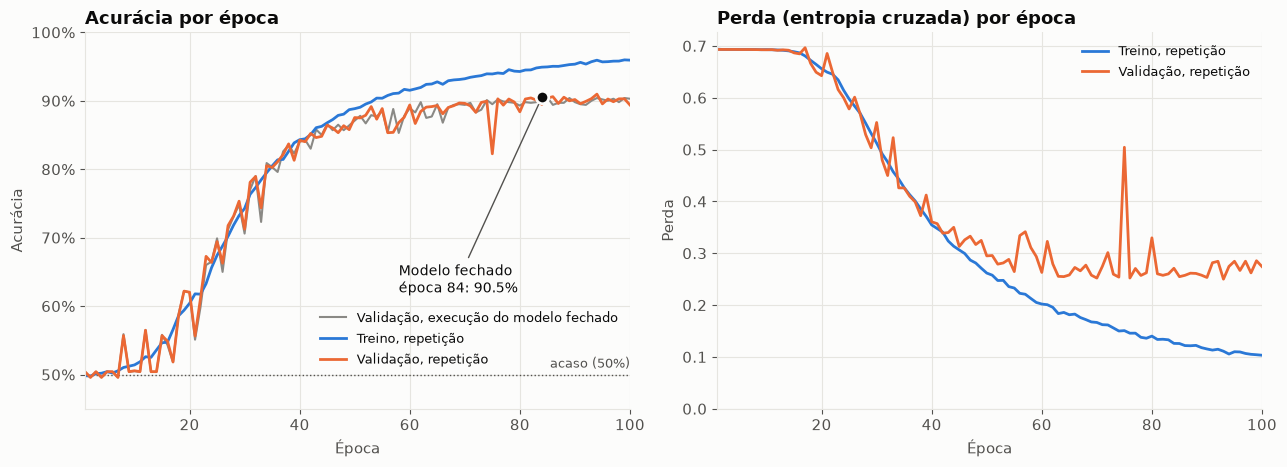

In [21]:
import json
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap

# Usa o modelo fechado, salvo na célula 19. Nada aqui treina de novo.
modelo.load_state_dict(torch.load("modelo_cats_and_dogs.pt", map_location=dispositivo))
modelo.eval()

AZUL, LARANJA, CINZA = "#2a78d6", "#eb6834", "#8a8985"
TINTA, TINTA_2, GRADE = "#0b0b0b", "#52514e", "#e6e5e0"
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
    "text.color": TINTA, "axes.labelcolor": TINTA_2, "xtick.color": TINTA_2, "ytick.color": TINTA_2,
    "axes.edgecolor": GRADE, "axes.grid": True, "grid.color": GRADE, "axes.axisbelow": True,
    "axes.spines.top": False, "axes.spines.right": False, "font.size": 11,
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left",
})

# A perda não foi registrada na execução da célula 19. Estas curvas vêm de uma repetição do
# treino, com a mesma configuração e a mesma seed, que não saiu idêntica por causa da GPU.
# Perda e acurácia de treino: média durante a época, com dropout ligado.
hist = json.load(open("historico_treino.json"))
rep = hist["repeticao"]
epocas = np.arange(1, 101)

fig, (ax_acc, ax_perda) = plt.subplots(1, 2, figsize=(13, 4.8))

ax_acc.axhline(0.5, color=TINTA_2, lw=1, ls=":")
ax_acc.text(100, 0.51, "acaso (50%)", color=TINTA_2, fontsize=9, ha="right")
ax_acc.plot(epocas, hist["acc_val_modelo_fechado"], color=CINZA, lw=1.5, label="Validação, execução do modelo fechado")
ax_acc.plot(epocas, rep["acc_treino"], color=AZUL, lw=2, label="Treino, repetição")
ax_acc.plot(epocas, rep["acc_val"], color=LARANJA, lw=2, label="Validação, repetição")
ep = hist["modelo_fechado_melhor_epoca"]
ax_acc.plot(ep, hist["acc_val_modelo_fechado"][ep - 1], "o", ms=9, color=TINTA, mec="#fcfcfb", mew=2, zorder=5)
ax_acc.annotate(f"Modelo fechado\népoca {ep}: {hist['acc_val_modelo_fechado'][ep - 1]:.1%}",
                (ep, hist["acc_val_modelo_fechado"][ep - 1]), xytext=(58, 0.62), color=TINTA, fontsize=10,
                arrowprops=dict(arrowstyle="-", color=TINTA_2, lw=1))
ax_acc.set(title="Acurácia por época", xlabel="Época", ylabel="Acurácia", xlim=(1, 100), ylim=(0.45, 1.0))
ax_acc.yaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
ax_acc.legend(frameon=False, loc="lower right", bbox_to_anchor=(1, 0.08), fontsize=9.5)

ax_perda.plot(epocas, rep["perda_treino"], color=AZUL, lw=2, label="Treino, repetição")
ax_perda.plot(epocas, rep["perda_val"], color=LARANJA, lw=2, label="Validação, repetição")
ax_perda.set(title="Perda (entropia cruzada) por época", xlabel="Época", ylabel="Perda", xlim=(1, 100), ylim=(0, None))
ax_perda.legend(frameon=False, loc="upper right", fontsize=9.5)

fig.tight_layout()
plt.show()

## 7. Avaliação final no Teste

In [20]:
print("Acurácia no teste:", acuracia(teste))

Acurácia no teste: 0.9100268576544315


#### Matriz de Confusão 

Acertos: 4066 de 4468 (0.9100)
gato      recall 89.4%   precisão 92.0%
cachorro  recall 92.5%   precisão 90.1%


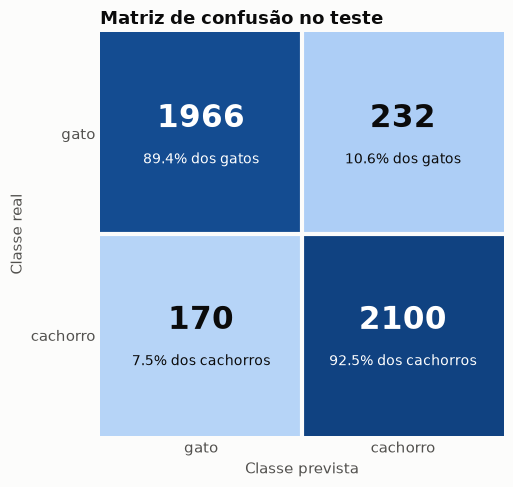

In [22]:
NOMES = {"Cat": "gato", "Dog": "cachorro"}
rotulos = [NOMES[c] for c in classes]

# Previsões do modelo fechado no conjunto de teste
probs = []
with torch.no_grad():
    for xb, _ in DataLoader(Subset(dados, teste), batch_size=32):
        probs.append(modelo(xb.to(dispositivo)).cpu())
probs = torch.cat(probs)
previsto = probs.argmax(dim=1)
real = y[teste]

matriz = np.zeros((2, 2), dtype=int)
for r_, p_ in zip(real.tolist(), previsto.tolist()):
    matriz[r_, p_] += 1

print(f"Acertos: {matriz.trace()} de {matriz.sum()} ({matriz.trace() / matriz.sum():.4f})")
for i, nome in enumerate(rotulos):
    print(f"{nome:9s} recall {matriz[i, i] / matriz[i].sum():.1%}   precisão {matriz[i, i] / matriz[:, i].sum():.1%}")

azuis = LinearSegmentedColormap.from_list("azuis", ["#cde2fb", "#6da7ec", "#2a78d6", "#104281"])
fig, ax = plt.subplots(figsize=(5.8, 5))
ax.imshow(matriz, cmap=azuis, vmin=0)
for i in range(2):
    for j in range(2):
        cor = "white" if matriz[i, j] > matriz.max() / 2 else TINTA
        ax.text(j, i - 0.07, f"{matriz[i, j]}", ha="center", va="center", color=cor, fontsize=22, fontweight="bold")
        ax.text(j, i + 0.13, f"{matriz[i, j] / matriz[i].sum():.1%} dos {rotulos[i]}s", ha="center", va="center", color=cor, fontsize=10)
ax.set(xticks=[0, 1], yticks=[0, 1], xticklabels=rotulos, yticklabels=rotulos,
       xlabel="Classe prevista", ylabel="Classe real", title="Matriz de confusão no teste")
ax.grid(False)
ax.tick_params(length=0)
for lado in ax.spines.values():
    lado.set_visible(False)
ax.set_xticks([0.5], minor=True)
ax.set_yticks([0.5], minor=True)
ax.grid(which="minor", color="#fcfcfb", lw=3)
ax.tick_params(which="minor", length=0)
fig.tight_layout()
plt.show()

#### Exemplos de imagens que foram classificadas errado

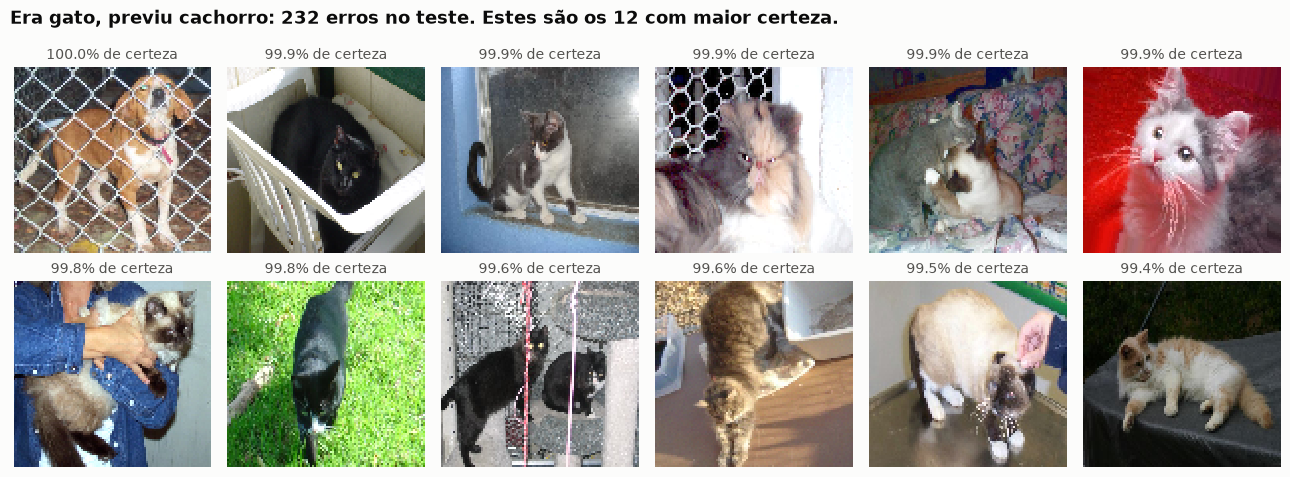

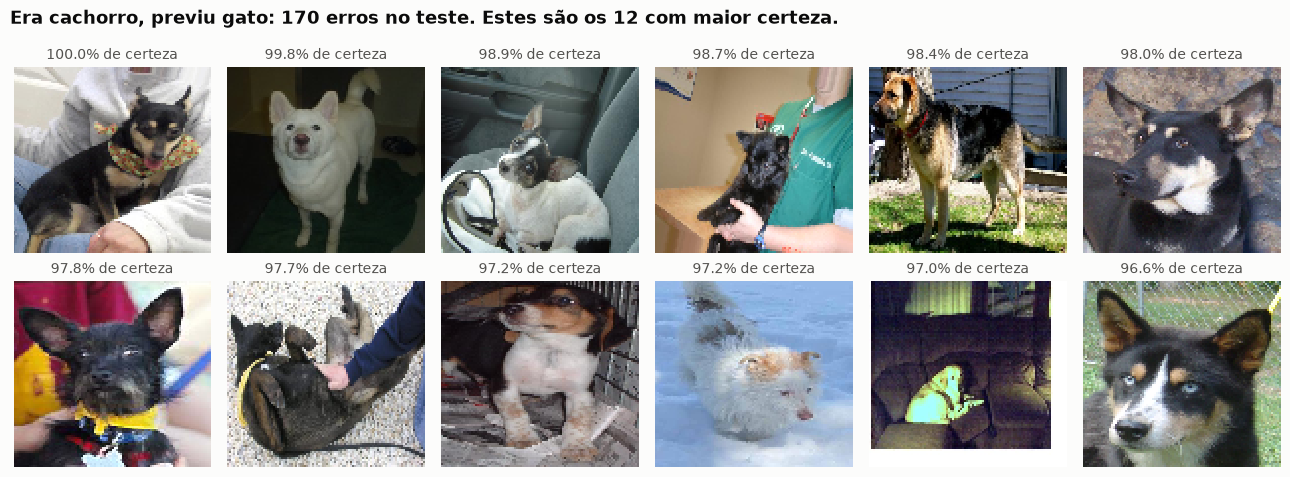

In [23]:
def mostrar_erros(classe_real, quantos=12):
    classe_prevista = 1 - classe_real
    erros = ((real == classe_real) & (previsto == classe_prevista)).nonzero().ravel()
    # Do mais confiante para o menos; uma imagem por origem, para não repetir a mesma foto.
    erros = erros[probs[erros, classe_prevista].argsort(descending=True)]
    vistos, escolhidos = set(), []
    for e in erros.tolist():
        origem = int(grupo[teste[e]])
        if origem not in vistos:
            vistos.add(origem)
            escolhidos.append(e)
        if len(escolhidos) == quantos:
            break

    colunas = 6
    linhas = int(np.ceil(len(escolhidos) / colunas))
    fig, eixos = plt.subplots(linhas, colunas, figsize=(13, 2.5 * linhas), squeeze=False)
    for ax in eixos.ravel():
        ax.axis("off")
    for ax, e in zip(eixos.ravel(), escolhidos):
        ax.imshow(X[teste[e]].permute(1, 2, 0).numpy(), interpolation="nearest")
        ax.set_title(f"{probs[e, classe_prevista]:.1%} de certeza", fontsize=10, fontweight="normal", color=TINTA_2, loc="center")
    fig.suptitle(f"Era {rotulos[classe_real]}, previu {rotulos[classe_prevista]}: "
                 f"{len(erros)} erros no teste. Estes são os {len(escolhidos)} com maior certeza.",
                 x=0.01, ha="left", fontsize=13, fontweight="bold")
    fig.tight_layout()
    plt.show()

mostrar_erros(classes.index("Cat"))
mostrar_erros(classes.index("Dog"))